# Stories Café: Weather and Seasons, by Branch

**Question:** does the weather (temperature, rain, wind) or the season (winter, spring, summer) change how much people buy, what they buy (iced vs hot drinks), and how they buy (dine-in vs takeaway, time of day), at each branch?

**Weather data:** daily Beirut weather for Jan 1 to Jun 30, 2026 from the [Open-Meteo historical weather archive](https://open-meteo.com/), already in the repo at `data/external/beirut_weather_2026H1.json`. It has the daily maximum and minimum temperature, total rain and maximum wind speed. The dataset doesn't say where the branches are, so we assume all three are in or near Beirut and share the same weather.

**Seasons** (meteorological, set in the first code cell):

| Season | Dates | Days |
|---|---|---|
| Winter | Jan 1 to Feb 28 | 59 |
| Spring | Mar 1 to May 31 | 92 |
| Summer | Jun 1 to Jun 30 | 30 |

The data ends on Jun 30, so "summer" is only its first month.

**Sections**
1. Setup
2. What the weather was like in each season
3. Orders by season, raw and trend-adjusted, by branch
4. Day-to-day weather vs demand: temperature, rain, wind
5. Rainy days by branch
6. Iced vs hot drinks
7. How people buy: dine-in vs takeaway, time of day
8. Conclusion

## 1. Setup

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates

# --- Season boundaries (month numbers) and the rainy-day threshold. Change and re-run. ---
SEASON_OF_MONTH = {1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring", 6: "Summer"}
SEASONS = ["Winter", "Spring", "Summer"]
RAINY_MM = 1.0  # a day with at least 1 mm of rain counts as rainy

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
# Seasons are ordered in time, so they use one hue light to dark
SEASON_COLORS = dict(zip(SEASONS, ["#86b6ef", "#256abf", "#0d366b"]))
ACCENT, WARM, MUTED = "#2a78d6", "#eb6834", "#b9b8b3"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"

weather = pd.DataFrame(json.loads(open("../data/external/beirut_weather_2026H1.json").read())["daily"])
weather["date"] = pd.to_datetime(weather.pop("time"))
weather = weather.set_index("date").rename(columns={
    "temperature_2m_max": "max_temp_c", "temperature_2m_min": "min_temp_c",
    "precipitation_sum": "rain_mm", "wind_speed_10m_max": "max_wind_kmh"})
weather["season"] = pd.Categorical(weather.index.month.map(SEASON_OF_MONTH), SEASONS, ordered=True)
weather["rainy"] = weather["rain_mm"] >= RAINY_MM

df = pd.read_csv("../data/stories_transactions.csv").drop_duplicates()  # 132 duplicate lines, as in 01_eda
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour
df = df.join(weather[["season", "rainy", "max_temp_c"]], on="Date")

# Drinks served cold vs hot (food is left out of this split)
ICED_PRODUCTS = {"Iced Matcha", "Strawberry Matcha"}
HOT_PRODUCTS = {"Classic Matcha", "Chai Latte", "Mint Tea", "English Breakfast Tea"}
df["serve"] = np.select(
    [df["Category"].isin(["Cold Coffee", "Cold Drinks"]) | df["Product"].isin(ICED_PRODUCTS),
     df["Category"].eq("Hot Coffee") | df["Product"].isin(HOT_PRODUCTS)],
    ["Iced drink", "Hot drink"], "Food")

orders = df.groupby("Transaction ID").agg(
    date=("Date", "first"), hour=("hour", "first"), branch=("Branch", "first"),
    order_type=("Order Type", "first"), revenue=(R, "sum"), items=("Quantity", "sum"))
orders = orders.join(weather[["season", "rainy", "max_temp_c", "rain_mm"]], on="date")
weather.head()

,max_temp_c,min_temp_c,rain_mm,max_wind_kmh,season,rainy
date,,,,,,
2026-01-01,16.0,12.7,72.8,30.3,Winter,True
2026-01-02,14.8,10.5,0.6,14.9,Winter,False
2026-01-03,14.6,8.4,0.0,11.3,Winter,False
2026-01-04,16.6,6.5,0.0,14.3,Winter,False
2026-01-05,19.9,9.9,0.0,18.5,Winter,False


## 2. What the weather was like in each season

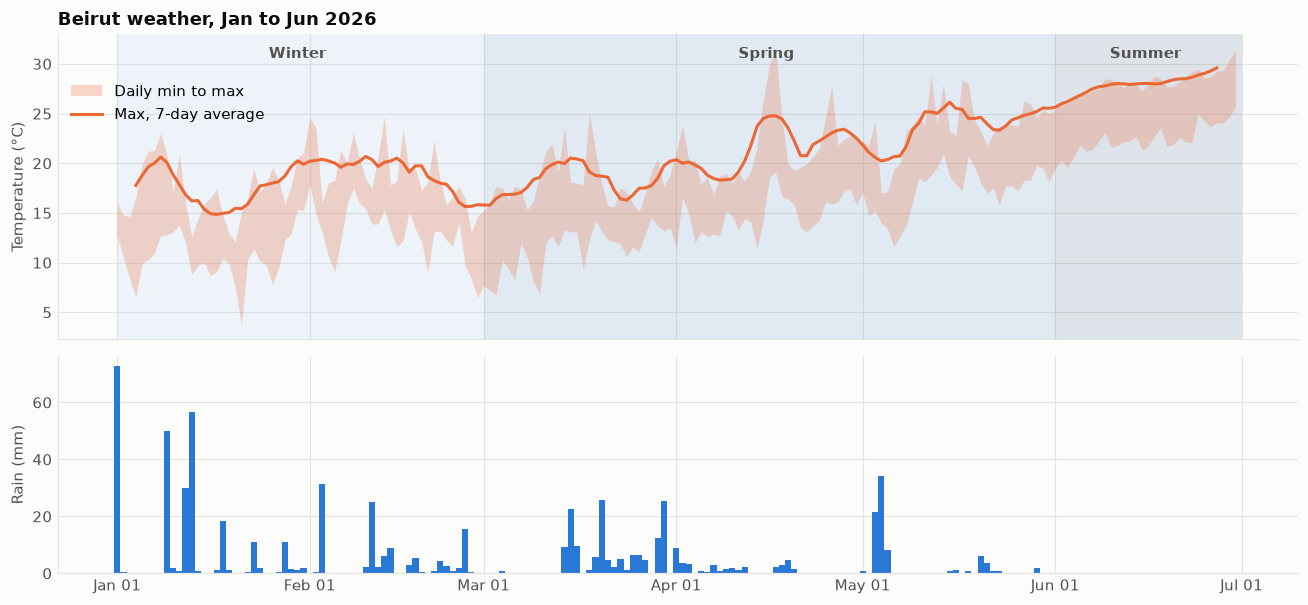

,days,avg_max_temp_c,avg_min_temp_c,total_rain_mm,rainy_days,avg_max_wind_kmh
season,,,,,,
Winter,59,18.2,11.6,377,27,20.3
Spring,92,21.1,14.4,265,36,18.0
Summer,30,28.1,22.4,0,0,12.1


In [2]:
season_weather = weather.groupby("season", observed=True).agg(
    days=("max_temp_c", "size"), avg_max_temp_c=("max_temp_c", "mean"), avg_min_temp_c=("min_temp_c", "mean"),
    total_rain_mm=("rain_mm", "sum"), rainy_days=("rainy", "sum"), avg_max_wind_kmh=("max_wind_kmh", "mean"))

fig, axes = plt.subplots(2, 1, figsize=(12, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
ax = axes[0]
for s in SEASONS:
    d = weather[weather["season"] == s]
    ax.axvspan(d.index.min(), d.index.max() + pd.Timedelta(days=1), color=SEASON_COLORS[s], alpha=0.12, lw=0)
    ax.text(d.index.min() + (d.index.max() - d.index.min()) / 2, 0.96, s, transform=ax.get_xaxis_transform(),
            ha="center", va="top", color=INK2, fontweight="bold")
ax.fill_between(weather.index, weather["min_temp_c"], weather["max_temp_c"], color=WARM, alpha=0.25, lw=0,
                label="Daily min to max")
ax.plot(weather.index, weather["max_temp_c"].rolling(7, center=True).mean(), color=WARM, label="Max, 7-day average")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Beirut weather, Jan to Jun 2026")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.88))
ax = axes[1]
ax.bar(weather.index, weather["rain_mm"], color=ACCENT, width=1)
ax.set_ylabel("Rain (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

season_weather.style.format("{:.1f}").format("{:.0f}", subset=["days", "rainy_days", "total_rain_mm"])

**Takeaway:** a real seasonal swing. Winter averaged about 18°C with 27 rainy days. Spring warmed to about 21°C, but still had 36 rainy days, mostly in March and April. June averaged about 28°C with no rain at all.

## 3. Orders by season, raw and trend-adjusted, by branch

Raw orders per day rise from winter to summer at every branch. But orders also grew steadily all six months (about +50%), so summer would look busier than winter even if the weather didn't matter.

To separate the season from the growth, we fit each branch's daily orders with a **growth trend + weekday effect** (no weather), and then look at what's left over. If a season or the weather matters, the leftover should be consistently positive or negative in that season.

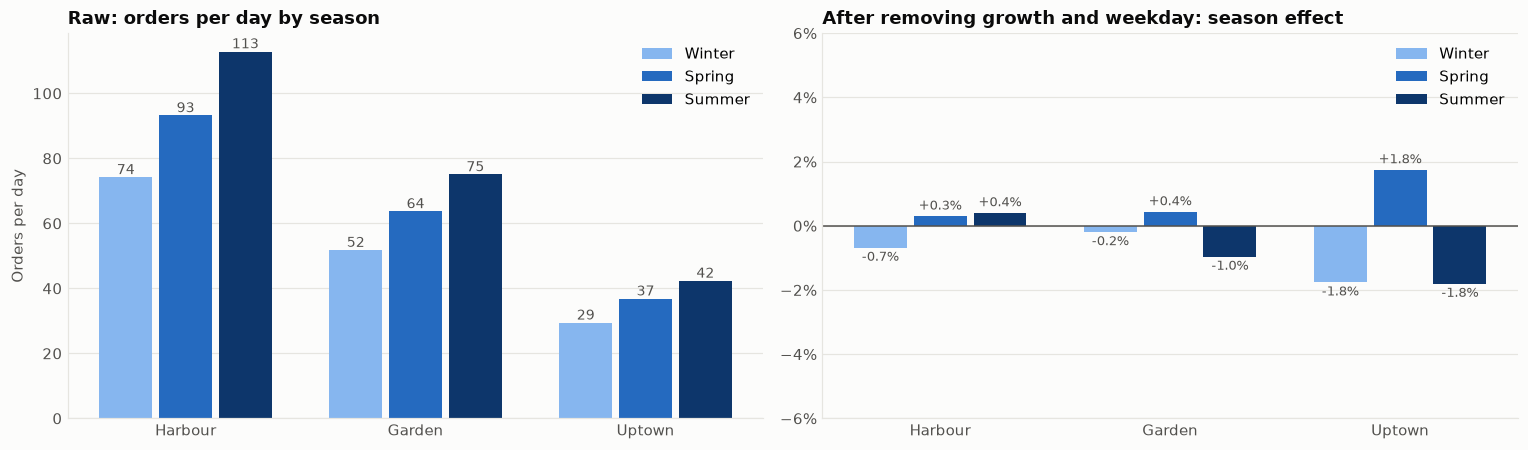

,All branches,Harbour,Garden,Uptown
season,,,,
Winter,-0.7%,-0.7%,-0.2%,-1.8%
Spring,+0.5%,+0.3%,+0.4%,+1.8%
Summer,-0.3%,+0.4%,-1.0%,-1.8%


In [3]:
daily = orders.groupby(["date", "branch"]).size().unstack()[BRANCHES]
daily["All branches"] = daily.sum(axis=1)


def leftover(daily_orders):
    """Log orders minus a trend + weekday fit: the share of demand the calendar does not explain."""
    t = (daily_orders.index - daily_orders.index[0]).days.to_numpy()
    dow = pd.get_dummies(daily_orders.index.dayofweek, drop_first=True).to_numpy(float)
    X = np.column_stack([np.ones(len(t)), t, dow])
    y = np.log(daily_orders.to_numpy())
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return pd.Series(y - X @ beta, index=daily_orders.index)


resid = pd.DataFrame({name: leftover(daily[name]) for name in ["All branches", *BRANCHES]}).join(weather)

raw = daily.groupby(weather["season"], observed=True).mean()[["All branches", *BRANCHES]]
adj = np.exp(resid.groupby("season", observed=True)[["All branches", *BRANCHES]].mean()) - 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
x = np.arange(len(BRANCHES))
w = 0.26
for i, s in enumerate(SEASONS):
    vals = raw.loc[s, BRANCHES].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=SEASON_COLORS[s], label=s)
    for xi, v in zip(x + (i - 1) * w, vals):
        ax.text(xi, v + 1, f"{v:.0f}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, BRANCHES)
ax.set_ylabel("Orders per day")
ax.set_title("Raw: orders per day by season")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)

ax = axes[1]
for i, s in enumerate(SEASONS):
    vals = adj.loc[s, BRANCHES].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=SEASON_COLORS[s], label=s)
    for xi, v in zip(x + (i - 1) * w, vals):
        ax.text(xi, v + (0.001 if v >= 0 else -0.001), f"{v:+.1%}", ha="center", va="bottom" if v >= 0 else "top",
                color=INK2, fontsize=8.5)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(x, BRANCHES)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(-0.06, 0.06)
ax.set_title("After removing growth and weekday: season effect")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

adj.style.format("{:+.1%}").set_caption("Orders vs the trend + weekday model, by season")

**Takeaway:** raw orders per day climb from winter to summer at every branch, but that's the general growth. Once growth and weekday are removed, **every season at every branch is within about 2% of expected**. Winter isn't quieter and summer isn't busier for weather reasons.

## 4. Day-to-day weather vs demand: temperature, rain, wind

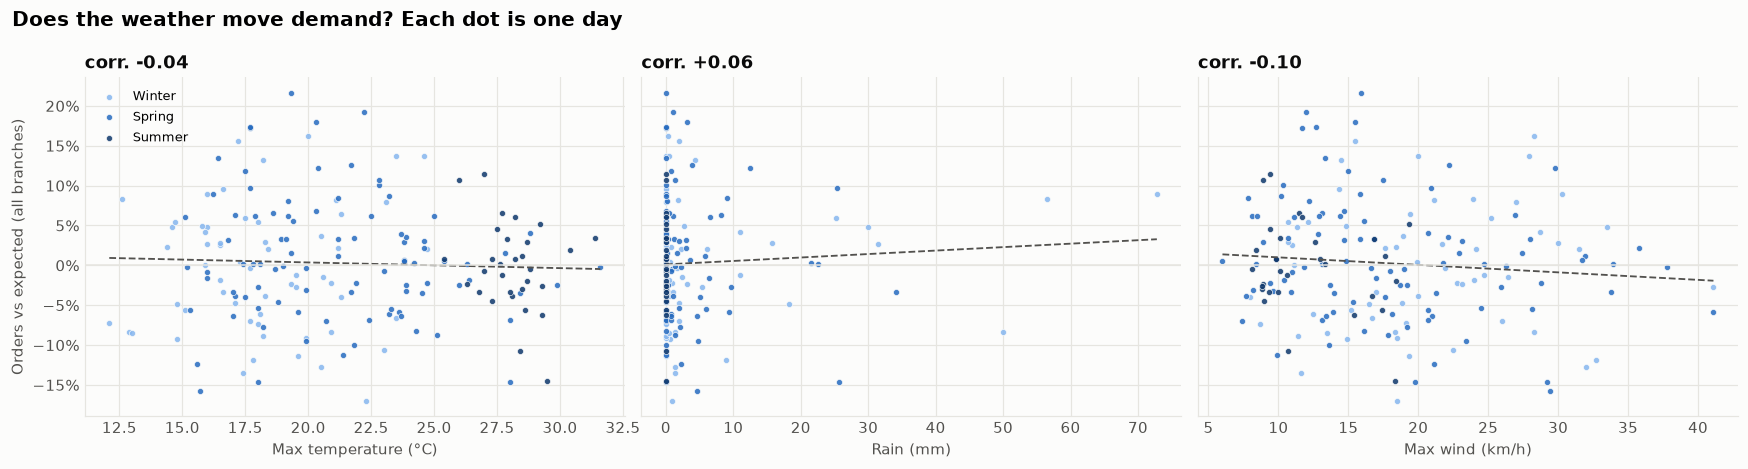

,All branches,Harbour,Garden,Uptown
Max temperature,-0.04,+0.02,-0.09,-0.01
Rain,+0.06,+0.11,+0.03,-0.07
Max wind,-0.10,-0.05,-0.12,+0.02


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
y = np.exp(resid["All branches"]) - 1
for ax, col, label in [(axes[0], "max_temp_c", "Max temperature (°C)"), (axes[1], "rain_mm", "Rain (mm)"),
                       (axes[2], "max_wind_kmh", "Max wind (km/h)")]:
    for s in SEASONS:
        m = resid["season"] == s
        ax.scatter(resid.loc[m, col], y[m], s=16, color=SEASON_COLORS[s], alpha=0.85, label=s,
                   edgecolors=SURFACE, linewidths=0.5)
    slope, icpt = np.polyfit(resid[col], y, 1)
    xs = np.linspace(resid[col].min(), resid[col].max(), 20)
    ax.plot(xs, icpt + slope * xs, color=INK2, lw=1.2, ls="--")
    ax.axhline(0, color=GRID, lw=1)
    ax.set_xlabel(label)
    ax.set_title(f"corr. {resid['All branches'].corr(resid[col]):+.2f}")
    ax.yaxis.set_major_formatter(pct)
axes[0].set_ylabel("Orders vs expected (all branches)")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Does the weather move demand? Each dot is one day", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

corr = pd.DataFrame({name: [resid[name].corr(resid[c]) for c in ["max_temp_c", "rain_mm", "max_wind_kmh"]]
                     for name in ["All branches", *BRANCHES]},
                    index=["Max temperature", "Rain", "Max wind"])
corr.style.format("{:+.2f}").set_caption("Correlation between weather and leftover demand (-1 to +1)")

**Takeaway:** the dots form flat clouds. Correlations between the weather and leftover demand are all **between -0.12 and +0.11** at every branch. As a rule of thumb, anything below about ±0.15 here could easily be chance, so neither heat, rain nor wind moves the number of orders.

## 5. Rainy days by branch

In [5]:
rain_lift = pd.DataFrame({
    name: [np.exp(resid.loc[resid["rainy"], name].mean() - resid.loc[~resid["rainy"], name].mean()) - 1]
    for name in ["All branches", *BRANCHES]}, index=["Rainy vs dry days"])
by_season = pd.DataFrame({
    s: [np.exp(resid.loc[(resid["season"] == s) & resid["rainy"], name].mean()
               - resid.loc[(resid["season"] == s) & ~resid["rainy"], name].mean()) - 1
        for name in ["All branches", *BRANCHES]]
    for s in ["Winter", "Spring"]}, index=["All branches", *BRANCHES]).T.rename(index=lambda s: f"Rainy vs dry, {s}")
pd.concat([rain_lift, by_season]).style.format("{:+.1%}").set_caption(
    f"Orders on rainy days (>= {RAINY_MM:g} mm) vs dry days, after growth and weekday (summer had no rain)")

,All branches,Harbour,Garden,Uptown
Rainy vs dry days,-0.0%,+1.4%,-0.1%,-2.7%
"Rainy vs dry, Winter",+0.8%,+2.0%,+4.4%,-6.8%
"Rainy vs dry, Spring",-0.6%,+1.6%,-3.6%,-1.0%


**Takeaway:** across the whole period, rainy days are **within about 3% of dry days at every branch**. Split by season, the numbers jump around more (from -7% at Uptown in winter to +4% at Garden in winter), but in both directions and on small numbers of days (27 rainy days in winter, 36 in spring), so there's no consistent rain effect. In a real café you'd usually expect rain to cut walk-in traffic and push customers toward staying longer or ordering takeaway; neither shows up here.

## 6. Iced vs hot drinks

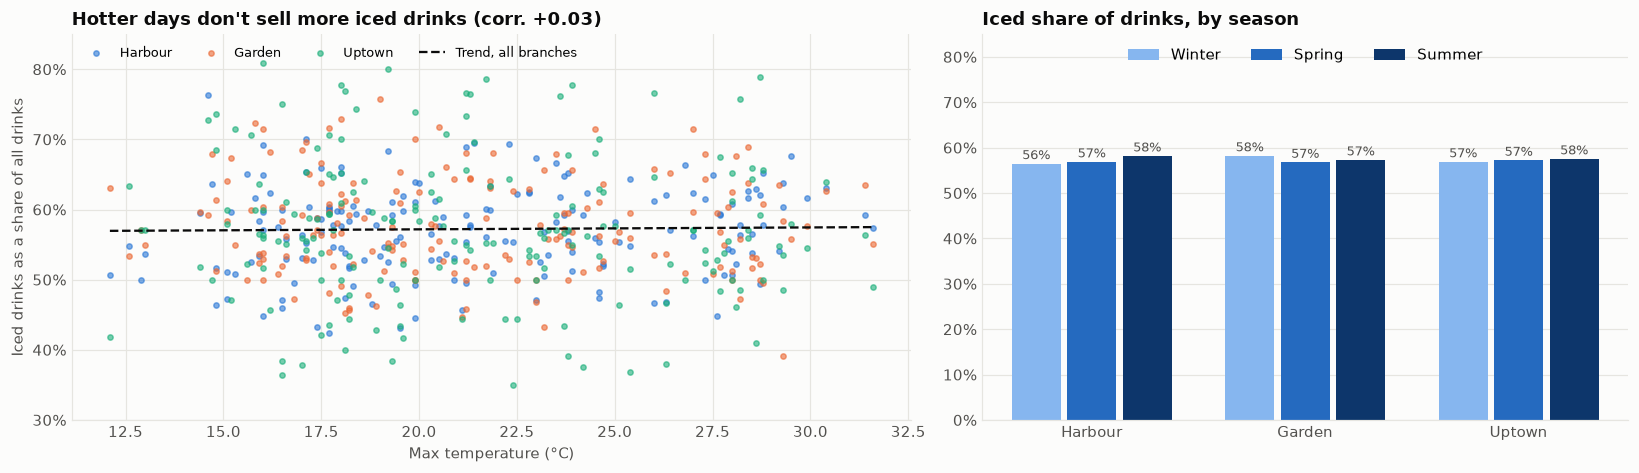

season,Winter,Spring,Summer
Branch,,,
Harbour,56.5%,56.8%,58.1%
Garden,58.2%,56.7%,57.3%
Uptown,56.9%,57.2%,57.5%


In [6]:
drinks = df[df["serve"] != "Food"]
share = (drinks.assign(iced=drinks["serve"].eq("Iced drink") * drinks["Quantity"])
         .groupby(["Date", "Branch"])[["iced", "Quantity"]].sum())
share["iced_share"] = share["iced"] / share["Quantity"]
share = share["iced_share"].unstack()[BRANCHES].join(weather[["max_temp_c", "season"]])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for b in BRANCHES:
    ax.scatter(share["max_temp_c"], share[b], s=12, color=BRANCH_COLORS[b], alpha=0.6, label=b)
temps = np.linspace(share["max_temp_c"].min(), share["max_temp_c"].max(), 20)
all_share = drinks.assign(iced=drinks["serve"].eq("Iced drink") * drinks["Quantity"]).groupby("Date")[["iced", "Quantity"]].sum()
all_share = (all_share["iced"] / all_share["Quantity"]).rename("all").to_frame().join(weather["max_temp_c"])
slope, icpt = np.polyfit(all_share["max_temp_c"], all_share["all"], 1)
ax.plot(temps, icpt + slope * temps, color=INK, lw=1.5, ls="--", label="Trend, all branches")
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0.3, 0.85)
ax.set_xlabel("Max temperature (°C)")
ax.set_ylabel("Iced drinks as a share of all drinks")
ax.set_title(f"Hotter days don't sell more iced drinks (corr. {all_share['all'].corr(all_share['max_temp_c']):+.2f})")
ax.legend(loc="upper left", ncols=4, fontsize=8.5)

ax = axes[1]
season_share = (drinks.assign(iced=drinks["serve"].eq("Iced drink") * drinks["Quantity"])
                .groupby(["Branch", "season"], observed=True)[["iced", "Quantity"]].sum())
season_share = (season_share["iced"] / season_share["Quantity"]).unstack()[SEASONS].loc[BRANCHES]
x = np.arange(len(BRANCHES))
w = 0.26
for i, s in enumerate(SEASONS):
    vals = season_share[s].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=SEASON_COLORS[s], label=s)
    for xi, v in zip(x + (i - 1) * w, vals):
        ax.text(xi, v + 0.01, f"{v:.0%}", ha="center", color=INK2, fontsize=8.5)
ax.set_xticks(x, BRANCHES)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.85)
ax.set_title("Iced share of drinks, by season")
ax.legend(loc="upper center", ncols=3)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
season_share.style.format("{:.1%}")

**How drinks are split:** iced = Cold Coffee, Cold Drinks, Iced Matcha and Strawberry Matcha; hot = Hot Coffee, Classic Matcha, Chai Latte, Mint Tea and English Breakfast Tea.

**Takeaway:** this is the clearest sign the data ignores the weather. **Iced drinks are about 57% of drinks in winter, spring and summer alike, at every branch**, even though June was about 10°C warmer than January. A real café in Beirut would sell far more iced drinks in June than in January.

## 7. How people buy: dine-in vs takeaway, time of day

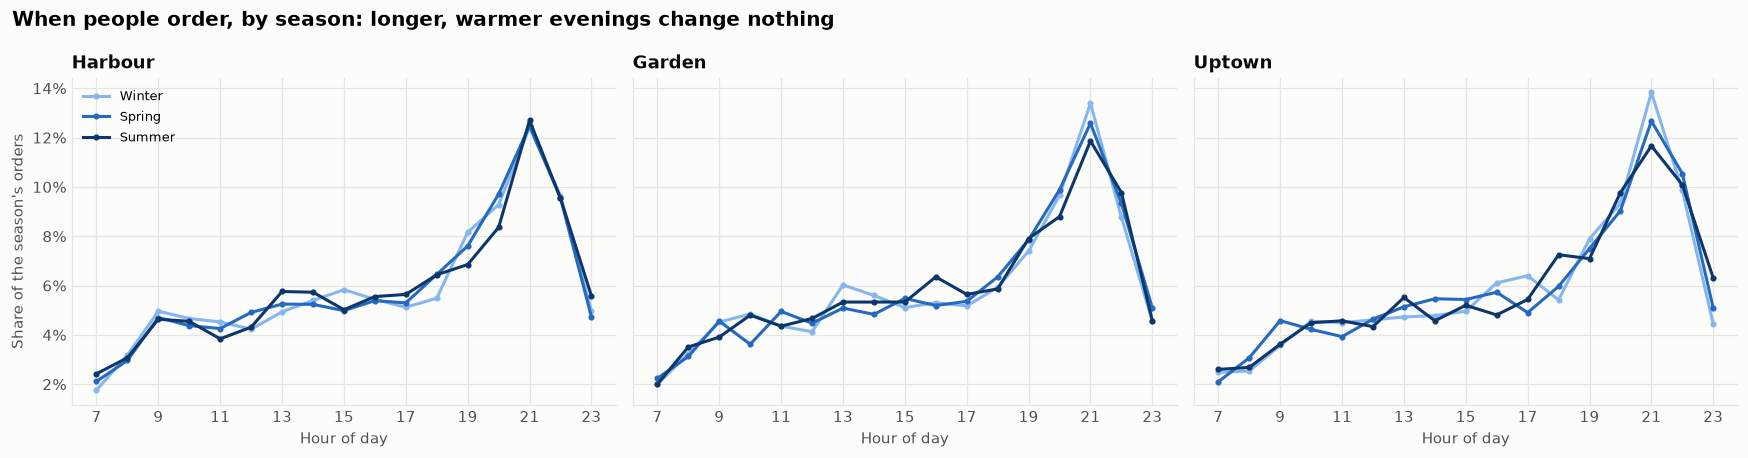

In [7]:
how = orders.groupby(["branch", "season"], observed=True).agg(
    takeaway_share=("order_type", lambda s: (s == "Takeaway").mean()),
    evening_share=("hour", lambda s: (s >= 18).mean()),
    aov=("revenue", "mean"))
rainy_how = orders.groupby(["branch", "rainy"]).agg(
    takeaway_share=("order_type", lambda s: (s == "Takeaway").mean()),
    evening_share=("hour", lambda s: (s >= 18).mean()))
rainy_how = rainy_how.rename(index={False: "Dry days", True: "Rainy days"}, level=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, b in zip(axes, BRANCHES):
    o = orders[orders["branch"] == b]
    mix = pd.crosstab(o["hour"], o["season"], normalize="columns")[SEASONS]
    for s in SEASONS:
        ax.plot(mix.index, mix[s], color=SEASON_COLORS[s], marker="o", ms=3, label=s)
    ax.set_title(b)
    ax.set_xticks(mix.index[::2])
    ax.set_xlabel("Hour of day")
    ax.yaxis.set_major_formatter(pct)
axes[0].set_ylabel("Share of the season's orders")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("When people order, by season: longer, warmer evenings change nothing", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

how.loc[BRANCHES].style.format({"takeaway_share": "{:.1%}", "evening_share": "{:.1%}", "aov": "${:.2f}"})

In [8]:
rainy_how.loc[BRANCHES].style.format("{:.1%}").set_caption("Rainy vs dry days")

**Takeaway:** the takeaway share (about 40%), evening share (about 50%) and order value (about $9) are the **same in every season and on rainy and dry days**, at all three branches. Summer's longer, warmer evenings don't shift visits later, and rain doesn't push people toward takeaway.

## 8. Conclusion

**The data shows no weather or season effect at any branch.**

| What we checked | Winter → Spring → Summer | Weather effect? |
|---|---|---|
| Weather | 18°C → 21°C → 28°C max; 27 → 36 → 0 rainy days | Real seasonal swing |
| Orders per day (raw) | Rising at every branch | That's the six-month growth trend |
| Orders after removing growth and weekday | Within about 2% in every season, every branch | None |
| Temperature, rain, wind vs demand | Correlations between -0.12 and +0.11 | None |
| Rainy vs dry days | Within about 3% at every branch overall; season-by-branch splits range from -7% to +4% with no consistent direction | None |
| Iced share of drinks | About 57% in every season, every branch | None, even with 10°C warmer days |
| Takeaway, time of day, order value | Same in every season and on rainy days | None |

**How to interpret this:**
1. **The dataset is synthetic** and was clearly generated without weather in mind. The flat iced-drink share is the giveaway: no real café in Beirut sells the same share of iced drinks in January as in June. This matches the war and holiday results (`02_war_impact`, `03_holidays`) and the team's pitch: demand here follows the calendar (trend and weekday), not outside events.
2. **For the pitch**, don't propose weather-based actions *from this data*. If you mention the weather, use it as evidence that the data follows a generated pattern, which is why the recommendations rely on its internal structure (prices, costs, customers).
3. **In real café data** you would usually expect: iced drinks rising sharply with temperature, fewer walk-ins on rainy days, more takeaway or delivery when it rains, later evening visits in summer, and seasonal menu opportunities (hot drinks and soups in winter, cold drinks and frozen desserts in summer). Weather forecasts are often used to plan stock and staff for exactly these reasons.

To change the seasons (for example astronomical seasons, with winter until Mar 19) or the rainy-day threshold, edit `SEASON_OF_MONTH` and `RAINY_MM` in the first code cell and re-run all cells.